# NEB from SMILES reactions
`neb_endpoints.py` (same folder) does the work:
1. **Atom mapping**: finds the smallest set of formed/broken bonds that makes the reactant graph isomorphic to the product graph (an autodE-style search, restricted to bond types whose counts change).
2. **Endpoints**: the side with fewer molecules is the template. Each molecule on the other side is Kabsch-aligned onto its mapped atoms (using the best of several conformers). The molecules are then moved apart rigidly so changing bonds sit at `shift × (r_cov,i + r_cov,j)` and no other pair is closer.
3. **NEB**: ASE NEB with IDPP interpolation and a climbing image, using whatever calculator you pass.

In [72]:
import numpy as np
import matplotlib.pyplot as plt
from ase.io import write
from ase.visualize import view
from IPython.display import display
from neb_endpoints import make_endpoints, relax, run_neb, plot_band

reactions = {
    "reaction_1": {"reactants": ["[N]=O", "O=S(=O)=O"], "products": ["O=NO[S@@](=O)[O]"]},
    "reaction_2": {"reactants": ["[N]=O", "O=S(=O)=O"], "products": ["O=S=O", "[O]N=O"]},
}
reactions = {
    "reaction_1":{"reactants":["[N][N]","O=O"],"products":["[N]=O","[N]=O"]},
    "reaction_2":{"reactants":["[N][N]","O=O"],"products":["[N][N]O[O]"]},
    "reaction_3":{"reactants":["[N][N]","O=O"],"products":["[O][N][N][O]"]}
}

## 1. Endpoints

In [73]:
endpoints = {}
for name, rxn in reactions.items():
    R, P = make_endpoints(rxn["reactants"], rxn["products"], shift=3)
    endpoints[name] = (R, P)
    write(f"{name}_endpoints.xyz", [R, P])

R, P = endpoints["reaction_2"]
print(R.info)                 # charge, mult (lowest spin), formed/broken bonds as atom indices
for a in (R, P):              # x3d shows one structure; view([R, P], viewer="ngl") with nglview
    display(view(a, viewer="x3d"))

[N][N] + O=O -> [N]=O + [N]=O | form: ['N0-O2', 'N1-O3']  break: ['N0-N1', 'O2-O3']
[N][N] + O=O -> [N][N]O[O] | form: ['N0-O2']  break: []
[N][N] + O=O -> [O][N][N][O] | form: ['N0-O2', 'N1-O3']  break: ['O2-O3']
{'charge': 0, 'mult': 1, 'n_radicals': 4, 'smiles': ['[N][N]', 'O=O'], 'formed': [(0, 2)], 'broken': []}


## 2. Calculator
Any ASE calculator works. Pass **one calculator** shared by all images (fine for MACE), or a **factory** `atoms -> Calculator` when it needs per-structure settings like charge/spin:
```python
from tblite.ase import TBLite
calc = lambda a: TBLite(method="GFN2-xTB", charge=a.info["charge"],
                        multiplicity=a.info["mult"], verbosity=0)
```

In [74]:
#from mace.calculators import mace_mp
from aimnet.calculators import AIMNet2ASE

#from chgnet.model.dynamics import CHGNetCalculator 

#calc = mace_mp(model="small", default_dtype="float64", device="cpu")
calc =  AIMNet2ASE("aimnet2")

## 3. (Optional) relax endpoints
Relaxing helps the NEB converge. A loose reactant complex can drift apart, so keep `steps` modest or skip this step.

In [75]:
RELAX = True
if RELAX:
    endpoints = {k: (relax(R, calc, steps=100), relax(P, calc, steps=100))
                 for k, (R, P) in endpoints.items()}

## 4. NEB

In [76]:
results = {}
for name, (R, P) in endpoints.items():
    images, E, Ea, dE = run_neb(R, P, calc, n_images=8, fmax=0.1,climb=False, steps=500,
                                trajectory=f"{name}_neb.traj", logfile=None)
    results[name] = images
    write(f"{name}_band.xyz", images)
    print(f"{name:12s}  Ea = {Ea:6.3f} eV   dE = {dE:6.3f} eV")

reaction_1    Ea =  2.191 eV   dE =  0.900 eV
reaction_2    Ea =  0.000 eV   dE = -0.021 eV
reaction_3    Ea =  2.193 eV   dE =  0.752 eV


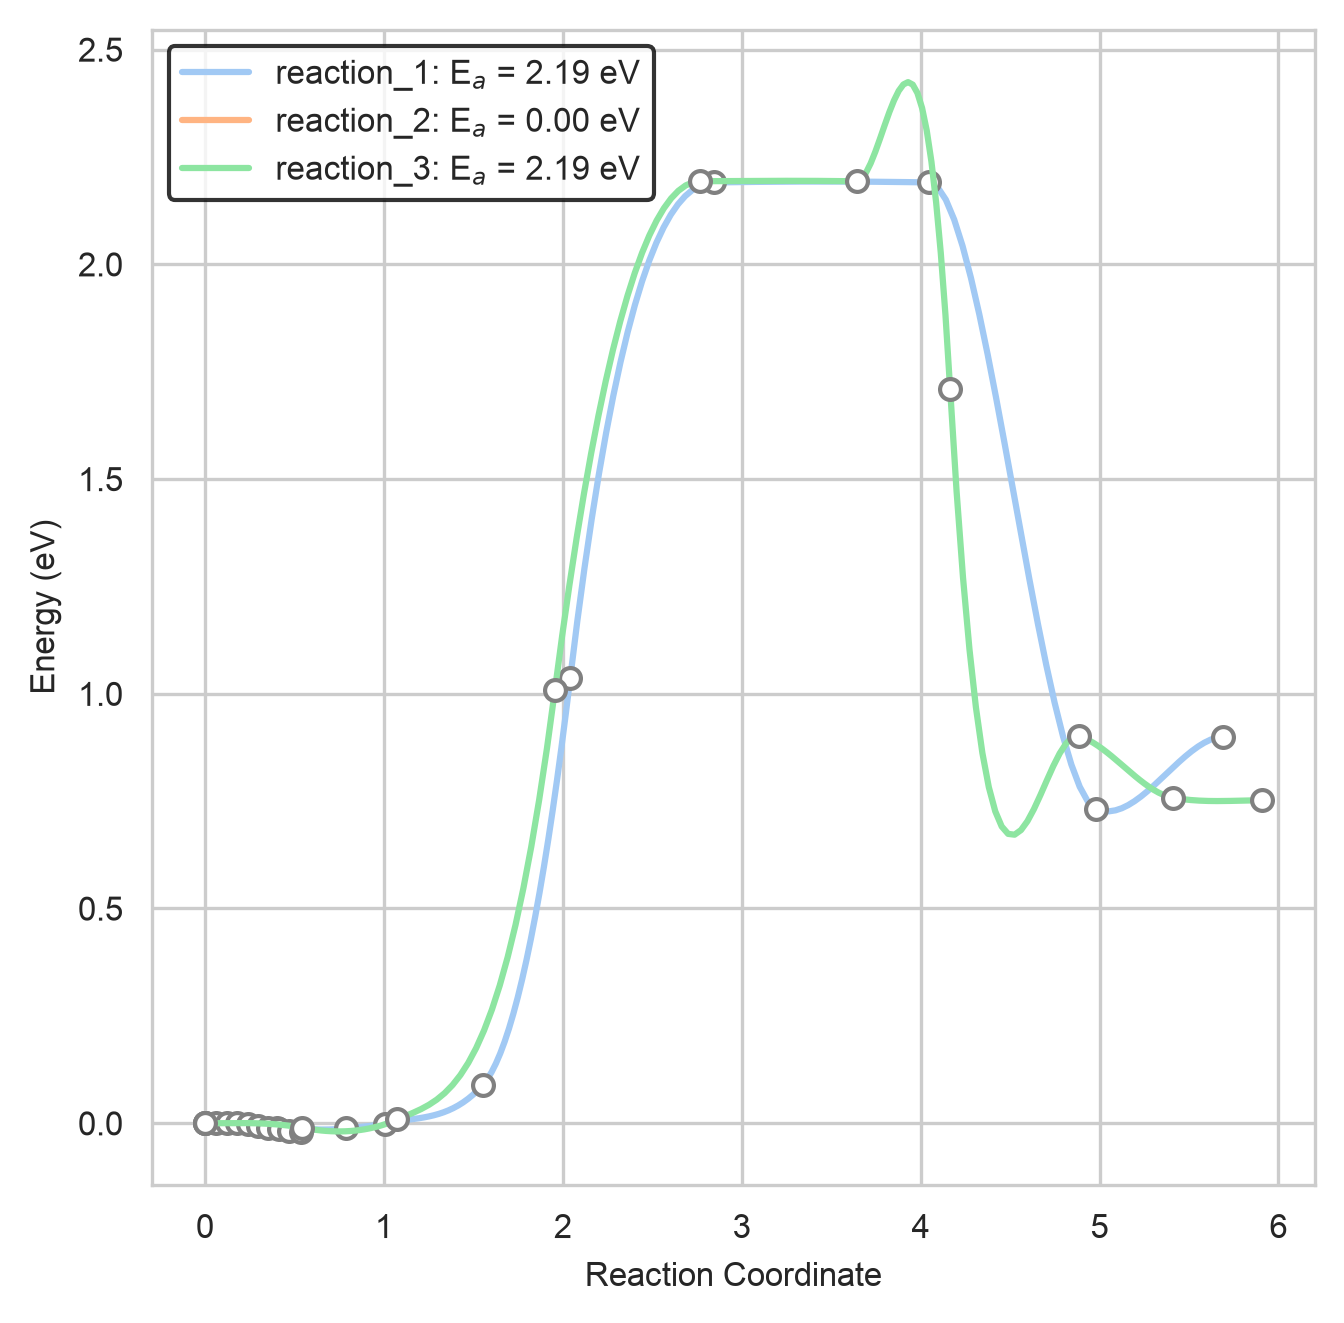

In [77]:
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import collections 

sns.set_style('whitegrid')
sns.set_palette('pastel')

def plot_nebruns(image_dict,ax,**kws):
    for k,v in image_dict.items():
        fit = forcecurve.fit_images(v)
        Ef = fit[1].max()
        ax.plot(fit[2],fit[3],label=f'{k}: E$_a$ = {Ef :.2F} eV')
        ax.plot(fit[0],fit[1],**kws)

kws = {'marker':'o',
       'linestyle':'None',
       'color':'grey',
       'markerfacecolor':'white',
       'markersize':5}

fig,ax = plt.subplots(ncols=1,nrows=1,figsize=(5,5),dpi=300,sharey=True,sharex=True)
plot_nebruns(image_dict=results,ax=ax,**kws)
ax.set_ylabel('Energy (eV)')
ax.set_xlabel('Reaction Coordinate')
    #flat_ax[i].set_title(f"expansion={nebbys[i]["expansion"]},rattle={nebbys[i]["rattle"]},nimages={nebbys[i]["nimages"]}")
ax.legend(edgecolor="black")